In [1]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, '.'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# R4 + C + fallback under helper failure

**Question.** How do R4+C, R4 + C + fallback and R6 hold up when the helper fails, and how much of R6's robustness
does the fallback alone give?

**Experiment.** Kuo's helper is forced to miss the leader's first copy of each TB with probability p (0.1 to 0.7).
- **data**: SCI-2A decoded, TB failed. In R6 the helper NACKs and the leader takes over.
- **sci**: SCI missed, the helper is silent. In R6 the leader's fallback takes over when no helper SCI is heard.

In R4+C the helper never relays a TB it did not decode, so both modes remove its copies. In R4 + C + fallback the
leader takes back the next handed slot when it hears no helper SCI there, in both modes.

**Data.** Periodic traffic, no background vehicles, 3 routes, 10 seeds; p = 0 is campaign v3 / v3_fb. Every run
uses the v3 command of the same cell and seed plus the miss flags, so arms pair by (route, p, mode, seed).
Intervals: 95 % Student-t; `*` = the paired interval excludes 0.

In [2]:
import glob, os, re, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
FIG = 'figures/helper_miss_fb'; os.makedirs(FIG, exist_ok=True)
SCN = {'hwy': 'Highway', 'rbt': 'Roundabout W', 'rbtE': 'Roundabout E'}
COLS = ['prr_mean', 'prr_min', 'tx_per_pkt', 'pkts', 'leader_tx', 'helper_tx', 'helper_forced_miss',
        'fallback_check', 'fallback_heard', 'fallback_tx', 'fallback_no_slot']
PAT = re.compile(r'(hwy|rbtE|rbt)_ivd30_periodic1tb_none(?:_p([\d.]+)_(data|sci))?_s(\d+)_run\.csv(?:\.gz)?$')
def load(pattern, arm, mode=None):
    rows = []
    for f in glob.glob(pattern):
        m = PAT.search(os.path.basename(f))
        if not m: continue
        sc, p, md_, s = m.groups()
        r = pd.read_csv(f).iloc[0]
        base = dict(arm=arm, sc=sc, seed=int(s), p=float(p) if p else 0.0)
        vals = {k: r[k] for k in COLS if k in r}
        if p:                                    # forced-miss run: its own mode
            rows.append(vals | base | dict(mode=md_))
        else:                                    # p = 0 baseline: same run for both modes
            rows += [vals | base | dict(mode=mo) for mo in ('data', 'sci')]
    return rows
R = []
for arm, src in [('R4_bsc', 'remote_v3'), ('R6', 'remote_v3'), ('R4_bsc_fb', 'remote_v3_fb')]:
    R += load(f'out/{src}/{arm}/*_ivd30_periodic1tb_none_s*_run.csv*', arm)
for d in ('local_helperrx', 'local_helperrx_fb'):
    for arm in ('R4_bsc', 'R4_bsc_fb', 'R4_bsc_fbs', 'R6'):
        R += load(f'out/{d}/controlled/{arm}/*_run.csv*', arm)   # R4_bsc_fbs: its p = 0 runs are here too
D = pd.DataFrame(R)
D['fb_tx_pkt'] = D.fallback_tx / D.pkts
D['miss_rate'] = D.helper_forced_miss.fillna(0) / D.pkts
print(len(D), 'rows'); display(D.groupby(['arm', 'mode', 'p']).size().unstack('p'))
ARM = {'R4_bsc': ('R4+C', '#e65100', '^'), 'R4_bsc_fb': ('R4 + C + fallback', '#8e24aa', 'v'),
       'R4_bsc_fbs': ('R4 + C + fallback, spaced', '#00838f', 's'), 'R6': ('R6', '#1b5e20', 'D')}
ARM = {a: v for a, v in ARM.items() if a in set(D.arm)}
def ci(x):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    return x.mean(), (stats.t.ppf(.975, len(x) - 1) * x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else np.nan)
def fmt(x, f=100):
    m, h = ci(f * np.asarray(x)); return f'{m:+.2f} ± {h:.2f}' + ('*' if abs(m) > h else ' ')

1440 rows


p                0.0  0.1  0.2  0.3  0.5  0.7
arm        mode                              
R4_bsc     data   30   30   30   30   30   30
           sci    30   30   30   30   30   30
R4_bsc_fb  data   30   30   30   30   30   30
           sci    30   30   30   30   30   30
R4_bsc_fbs data   30   30   30   30   30   30
           sci    30   30   30   30   30   30
R6         data   30   30   30   30   30   30
           sci    30   30   30   30   30   30

## 1. Group and worst-member PRR against the forced miss probability

Solid: mode data, dashed: mode sci. Mean over seeds, 95 % interval.

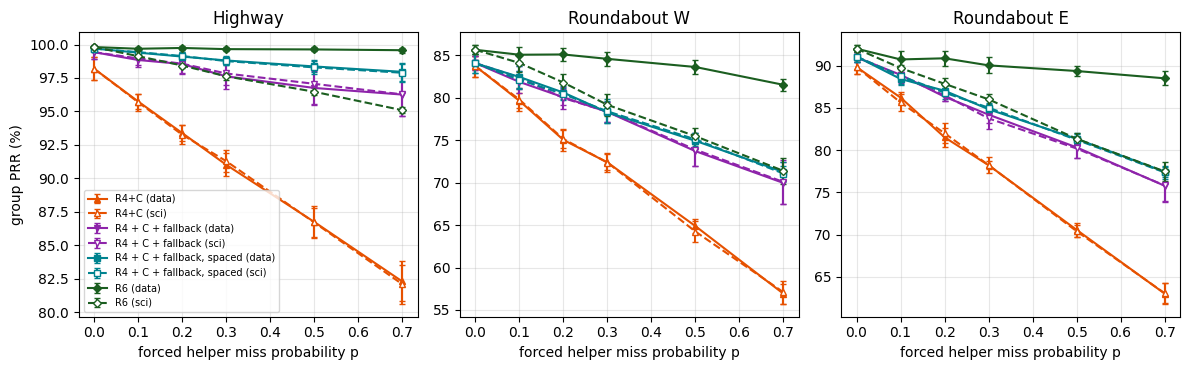

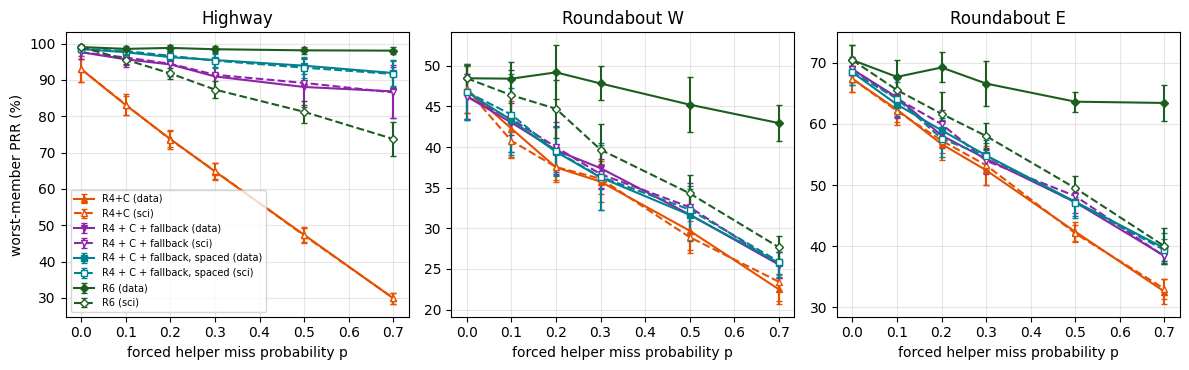

In [3]:
for y, lab, fn in [('prr_mean', 'group PRR (%)', 'prr'), ('prr_min', 'worst-member PRR (%)', 'worst')]:
    fig, axs = plt.subplots(1, 3, figsize=(12, 3.8))
    for a, sc in zip(axs, SCN):
        for arm, (l, col, mk) in ARM.items():
            for mode, ls in (('data', '-'), ('sci', '--')):
                q = D[(D.arm == arm) & (D.sc == sc) & (D['mode'] == mode)]
                if q.empty: continue
                g = q.groupby('p')[y].apply(lambda v: ci(100 * v)).apply(pd.Series)
                a.errorbar(g.index, g[0], yerr=g[1], color=col, marker=mk, ls=ls, ms=4, capsize=2,
                           mfc='white' if mode == 'sci' else col, label=f'{l} ({mode})')
        a.set_title(SCN[sc]); a.set_xlabel('forced helper miss probability p'); a.grid(alpha=.3)
    axs[0].set_ylabel(lab); axs[0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(f'{FIG}/{fn}_vs_p.pdf'); fig.savefig(f'{FIG}/{fn}_vs_p.png', dpi=160); plt.show()

## 2. Paired gains (pp): fallback over R4+C, and what is left to R6

Per route, mode and p, paired by seed. `share` = (R4+C+fb − R4+C) / (R6 − R4+C) on the group PRR.

In [4]:
K = ['sc', 'mode', 'p', 'seed']
W = D.pivot_table(index=K, columns='arm', values=['prr_mean', 'prr_min', 'tx_per_pkt']).dropna()
rows = []
for (sc, mode, p), q in W.groupby(level=['sc', 'mode', 'p']):
    g6 = (q.prr_mean.R6 - q.prr_mean.R4_bsc).mean()
    rows.append({'route': SCN[sc], 'mode': mode, 'p': p, 'n': len(q),
                 'fb − R4+C': fmt(q.prr_mean.R4_bsc_fb - q.prr_mean.R4_bsc),
                 'R6 − fb': fmt(q.prr_mean.R6 - q.prr_mean.R4_bsc_fb),
                 'share (%)': round(100 * (q.prr_mean.R4_bsc_fb - q.prr_mean.R4_bsc).mean() / g6) if abs(g6) > 1e-3 else np.nan,
                 'worst: fb − R4+C': fmt(q.prr_min.R4_bsc_fb - q.prr_min.R4_bsc),
                 'worst: R6 − fb': fmt(q.prr_min.R6 - q.prr_min.R4_bsc_fb),
                 'tx/pkt: fb − R4+C': fmt(q.tx_per_pkt.R4_bsc_fb - q.tx_per_pkt.R4_bsc, 1),
                 'tx/pkt: R6 − fb': fmt(q.tx_per_pkt.R6 - q.tx_per_pkt.R4_bsc_fb, 1)}
                | ({'spaced − fb': fmt(q.prr_mean.R4_bsc_fbs - q.prr_mean.R4_bsc_fb),
                    'R6 − spaced': fmt(q.prr_mean.R6 - q.prr_mean.R4_bsc_fbs),
                    'share spaced (%)': round(100 * (q.prr_mean.R4_bsc_fbs - q.prr_mean.R4_bsc).mean() / g6)
                    if abs(g6) > 1e-3 else np.nan,
                    'worst: R6 − spaced': fmt(q.prr_min.R6 - q.prr_min.R4_bsc_fbs),
                    'tx/pkt: spaced − fb': fmt(q.tx_per_pkt.R4_bsc_fbs - q.tx_per_pkt.R4_bsc_fb, 1)}
                   if 'R4_bsc_fbs' in q.prr_mean else {}))
G = pd.DataFrame(rows).set_index(['route', 'mode', 'p'])
with pd.option_context('display.max_rows', 200, 'display.width', 250):
    display(G)

n       fb − R4+C         R6 − fb  share (%) worst: fb − R4+C  worst: R6 − fb tx/pkt: fb − R4+C tx/pkt: R6 − fb    spaced − fb     R6 − spaced  share spaced (%) worst: R6 − spaced tx/pkt: spaced − fb
route        mode p                                                                                                                                                                                                            
Highway      data 0.0  10   +1.24 ± 0.61*   +0.38 ± 0.47          76    +4.67 ± 2.63*   +1.43 ± 1.64      +0.06 ± 0.04*   -1.17 ± 0.09*  +0.27 ± 0.49    +0.11 ± 0.09*                93      +0.52 ± 0.73        +0.02 ± 0.03 
                  0.1  10   +3.10 ± 0.40*   +0.84 ± 0.45*         79   +12.60 ± 2.02*   +2.88 ± 1.80*     +0.15 ± 0.02*   -1.00 ± 0.08*  +0.55 ± 0.43*   +0.29 ± 0.12*                93      +0.93 ± 0.83*       +0.02 ± 0.01*
                  0.2  10   +5.16 ± 0.56*   +1.20 ± 0.56*         81   +20.54 ± 2.15*   +4.55 ± 2.54*     +0.25 ± 0.02*   -0.87 ± 0.08*  +0.56 ± 0.47*   +0.64 ± 0.26*                90      +2.54 ± 1.36*       +0.03 ± 0.03 
                  0.3  10   +6.61 ± 0.82*   +2.03 ± 0.96*         76   +26.16 ± 3.48*   +7.48 ± 3.85*     +0.31 ± 0.04*   -0.67 ± 0.09*  +1.18 ± 0.92*   +0.85 ± 0.28*                90      +2.98 ± 1.48*       +0.06 ± 0.04*
                  0.5  10  +10.02 ± 1.04*   +2.88 ± 1.18*         78   +40.68 ± 4.36*  +10.08 ± 4.39*     +0.48 ± 0.05*   -0.37 ± 0.10*  +1.61 ± 1.05*   +1.27 ± 0.33*                90      +4.23 ± 1.74*       +0.07 ± 0.05*
                  0.7  10  +13.97 ± 1.85*   +3.32 ± 1.54*         81   +56.94 ± 7.12*  +11.21 ± 6.87*     +0.66 ± 0.07*   -0.08 ± 0.10   +1.70 ± 1.47*   +1.62 ± 0.51*                91      +6.16 ± 2.76*       +0.07 ± 0.07 
             sci  0.0  10   +1.24 ± 0.61*   +0.38 ± 0.47          76    +4.67 ± 2.63*   +1.43 ± 1.64      +0.06 ± 0.04*   -1.17 ± 0.09*  +0.27 ± 0.49    +0.11 ± 0.09*                93      +0.52 ± 0.73        +0.02 ± 0.03 
                  0.1  10   +3.27 ± 0.36*   +0.17 ± 0.46          95   +13.00 ± 1.81*   -0.60 ± 2.09      +0.16 ± 0.03*   -1.08 ± 0.08*  +0.47 ± 0.44*   -0.30 ± 0.16*               109      -2.37 ± 1.45*       +0.02 ± 0.02 
                  0.2  10   +5.31 ± 0.66*   -0.14 ± 0.88         103   +20.87 ± 2.89*   -2.66 ± 4.41      +0.25 ± 0.03*   -0.98 ± 0.09*  +0.57 ± 0.64    -0.71 ± 0.32*               114      -4.85 ± 2.55*       +0.03 ± 0.04 
                  0.3  10   +6.55 ± 0.93*   -0.21 ± 0.92         103   +26.48 ± 3.52*   -4.08 ± 4.65      +0.32 ± 0.04*   -0.88 ± 0.09*  +0.93 ± 0.78*   -1.14 ± 0.31*               118      -7.97 ± 3.54*       +0.05 ± 0.04*
                  0.5  10  +10.37 ± 1.47*   -0.59 ± 1.60         106   +41.97 ± 6.12*   -7.95 ± 7.86*     +0.49 ± 0.08*   -0.69 ± 0.11*  +1.23 ± 1.43    -1.82 ± 0.33*               119     -12.15 ± 4.97*       +0.06 ± 0.08 
                  0.7  10  +14.19 ± 1.79*   -1.18 ± 1.61         109   +56.58 ± 6.85*  -12.80 ± 8.24*     +0.65 ± 0.07*   -0.52 ± 0.10*  +1.62 ± 1.46*   -2.80 ± 0.61*               122     -17.89 ± 7.45*       +0.07 ± 0.07 
Roundabout W data 0.0  10   +0.36 ± 1.44    +1.56 ± 0.73*         19    -0.88 ± 2.92    +2.24 ± 1.92*     +0.03 ± 0.03*   -0.31 ± 0.03*  -0.02 ± 1.01    +1.59 ± 0.81*                18      +1.69 ± 3.07        +0.01 ± 0.02 
                  0.1  10   +2.23 ± 1.06*   +3.20 ± 1.73*         41    +0.74 ± 3.60    +5.40 ± 4.30*     +0.14 ± 0.03*   -0.21 ± 0.03*  +0.58 ± 0.85    +2.62 ± 1.53*                52      +5.11 ± 4.27*       +0.02 ± 0.02 
                  0.2  10   +5.03 ± 1.25*   +5.04 ± 1.16*         50    +2.11 ± 2.49    +9.58 ± 3.92*     +0.24 ± 0.04*   -0.09 ± 0.03*  +0.55 ± 0.90    +4.49 ± 1.34*                55      +9.77 ± 4.07*       +0.02 ± 0.02 
                  0.3  10   +5.94 ± 1.32*   +6.26 ± 1.03*         49    +1.66 ± 2.72   +10.42 ± 3.72*     +0.29 ± 0.03*   +0.04 ± 0.04   -0.04 ± 1.21    +6.30 ± 1.21*                48     +11.56 ± 4.85*       +0.03 

## 3. Fallback mechanics

Forced misses and leader takeovers per packet (R4 + C + fallback and R6), and transmissions per packet.

miss_rate                   fb_tx_pkt                    \
arm           R4_bsc_fb R4_bsc_fbs     R6 R4_bsc_fb R4_bsc_fbs     R6   
sc   mode p                                                             
hwy  data 0.0     0.000      0.000  0.000     0.060      0.070  0.012   
          0.1     0.104      0.104  0.104     0.150      0.176  0.010   
          0.2     0.208      0.207  0.208     0.243      0.277  0.010   
          0.3     0.309      0.310  0.310     0.318      0.366  0.008   
          0.5     0.511      0.512  0.512     0.490      0.556  0.010   
          0.7     0.707      0.704  0.707     0.672      0.742  0.008   
     sci  0.0     0.000      0.000  0.000     0.060      0.070  0.012   
          0.1     0.104      0.104  0.105     0.150      0.177  0.081   
          0.2     0.207      0.208  0.208     0.242      0.274  0.146   
          0.3     0.310      0.310  0.310     0.324      0.371  0.205   
          0.5     0.513      0.511  0.511     0.503      0.556  0.351   
          0.7     0.708      0.706  0.707     0.663      0.740  0.473   
rbt  data 0.0     0.000      0.000  0.000     0.069      0.088  0.006   
          0.1     0.159      0.158  0.158     0.202      0.225  0.003   
          0.2     0.326      0.325  0.325     0.350      0.396  0.006   
          0.3     0.488      0.489  0.487     0.496      0.543  0.005   
          0.5     0.844      0.843  0.843     0.803      0.892  0.004   
          0.7     1.189      1.187  1.187     1.078      1.219  0.004   
     sci  0.0     0.000      0.000  0.000     0.069      0.088  0.006   
          0.1     0.159      0.159  0.159     0.204      0.236  0.119   
          0.2     0.325      0.325  0.327     0.350      0.390  0.244   
          0.3     0.488      0.489  0.488     0.489      0.541  0.359   
          0.5     0.844      0.844  0.844     0.791      0.887  0.617   
          0.7     1.187      1.189  1.188     1.093      1.217  0.874   
rbtE data 0.0     0.000      0.000  0.000     0.050      0.064  0.003   
          0.1     0.138      0.138  0.138     0.161      0.204  0.005   
          0.2     0.280      0.280  0.280     0.297      0.333  0.004   
          0.3     0.428      0.428  0.426     0.417      0.469  0.006   
          0.5     0.736      0.738  0.736     0.703      0.767  0.002   
          0.7     1.048      1.049  1.049     0.945      1.073  0.002   
     sci  0.0     0.000      0.000  0.000     0.050      0.064  0.003   
          0.1     0.139      0.139  0.139     0.167      0.198  0.108   
          0.2     0.280      0.280  0.280     0.296      0.334  0.217   
          0.3     0.427      0.428  0.427     0.423      0.467  0.327   
          0.5     0.737      0.737  0.737     0.693      0.770  0.556   
          0.7     1.048      1.048  1.049     0.957      1.073  0.796   

              no_slot_pkt                   tx_per_pkt                    
arm             R4_bsc_fb R4_bsc_fbs     R6  R4_bsc_fb R4_bsc_fbs     R6  
sc   mode p                                                               
hwy  data 0.0       0.015        0.0  0.000      2.921      2.940  1.751  
          0.1       0.027        0.0  0.001      2.807      2.832  1.804  
          0.2       0.030        0.0  0.001      2.711      2.737  1.844  
          0.3       0.054        0.0  0.001      2.590      2.647  1.920  
          0.5       0.070        0.0  0.001      2.389      2.460  2.018  
          0.7       0.069        0.0  0.001      2.211      2.279  2.127  
     sci  0.0       0.015        0.0  0.000      2.921      2.940  1.751  
          0.1       0.022        0.0  0.000      2.819      2.834  1.736  
          0.2       0.030        0.0  0.000      2.708      2.737  1.725  
          0.3       0.049        0.0  0.000      2.597      2.643  1.712  
          0.5       0.060        0.0  0.000      2.397      2.460  1.706  
          0.7       0.076        0.0  0.000      2.209      2.282  1.688  
rbt  data 0.0       0.011        0.0  0.0

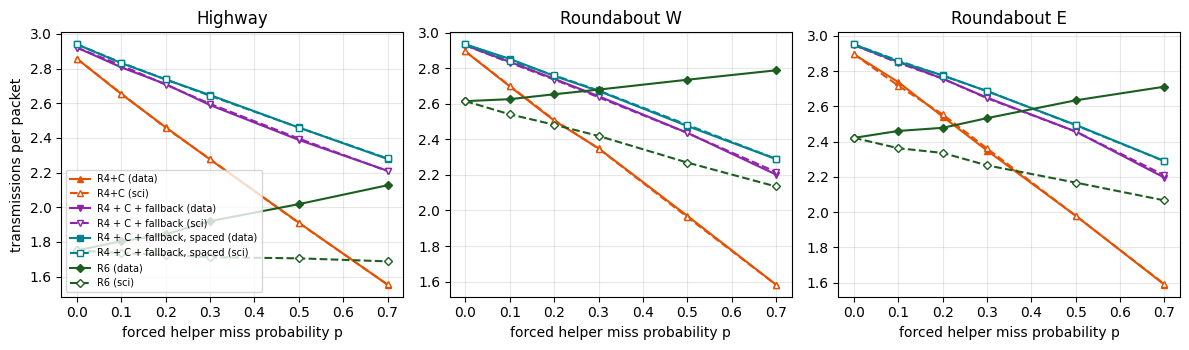

In [5]:
D['no_slot_pkt'] = D.get('fallback_no_slot', np.nan) / D.pkts
T = D[D.arm.isin(['R4_bsc_fb', 'R4_bsc_fbs', 'R6'])].groupby(['sc', 'mode', 'p', 'arm'])[['miss_rate', 'fb_tx_pkt', 'no_slot_pkt', 'tx_per_pkt']].mean()
with pd.option_context('display.max_rows', 200):
    display(T.unstack('arm').round(3))
fig, axs = plt.subplots(1, 3, figsize=(12, 3.6))
for a, sc in zip(axs, SCN):
    for arm, (l, col, mk) in ARM.items():
        for mode, ls in (('data', '-'), ('sci', '--')):
            q = D[(D.arm == arm) & (D.sc == sc) & (D['mode'] == mode)].groupby('p').tx_per_pkt.mean()
            a.plot(q.index, q.values, color=col, marker=mk, ls=ls, ms=4, mfc='white' if mode == 'sci' else col,
                   label=f'{l} ({mode})')
    a.set_title(SCN[sc]); a.set_xlabel('forced helper miss probability p'); a.grid(alpha=.3)
axs[0].set_ylabel('transmissions per packet'); axs[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{FIG}/tx_vs_p.pdf'); fig.savefig(f'{FIG}/tx_vs_p.png', dpi=160); plt.show()

## 4. Findings

450 / 450 new runs (2026-11-22), 0 failed; every arm, mode and p has 30 runs (3 routes x 10 seeds).

**The miss mode does not matter without feedback.** R4+C and R4 + C + fallback give the same PRR in modes data and sci
(within 1 pp): without HARQ feedback the helper either relays or does not, and the leader only checks whether a
helper SCI comes. Only R6 tells the modes apart.

**The fallback removes most of R4+C's loss to helper failure.** Group PRR, p = 0 → 0.7:
- **Highway:** R4+C 98.2 → 82.3 %, R4 + C + fallback 99.4 → 96.3 %. **Roundabout W:** 83.7 → 56.9 % against
  84.1 → 70.0 %. **Roundabout E:** 89.8 → 63.0 % against 91.0 → 75.8 %.
- **Paired gain over R4+C:** grows almost linearly with p, from +2.2 to +3.3 pp at p = 0.1 to +12.8 to +14.2 pp at
  p = 0.7. It is significant at every p > 0 on every route.
- **Worst member:**
  - On the highway the fallback holds it at 86.8 % at p = 0.7, against 29.9 % for R4+C (+57 pp).
  - On the roundabouts the worst member still falls: 25.5 % (W) and 38.4 % (E) at p = 0.7. The gain over R4+C is
    only +2 to +6 pp, likely because the blocked member does not hear the leader's copy either.
- **Cost:** +0.11 to +0.66 transmissions per packet over R4+C. Yet its total still falls with p (2.9 → 2.2), because
  a lost helper relay is replaced by one leader copy, not by the two or more blind relays.

**Against R6, the mode decides.**
- **Mode data (the helper NACKs):** R6 hardly notices the failure (highway 99.8 → 99.6 %, W 85.7 → 81.5 %,
  E 92.0 → 88.5 %; worst member 98.0 / 43.0 / 63.4 % at p = 0.7). The NACK brings the leader back at once and the
  members' feedback drives the retransmissions.
  - On the highway R4 + C + fallback gets 76–81 % of R6's gain over R4+C; R6 stays 0.8–3.3 pp ahead.
  - On the roundabouts the fallback gets only about half (41–60 %). R6 is 2–13 pp ahead in group PRR and 3–25 pp
    for the worst member.
- **Mode sci (the helper is silent):** R6 has only the same fallback, and R4 + C + fallback catches up.
  - Highway: level in group PRR at every p; at p = 0.5–0.7 it is ahead for the worst member (86.5 vs 73.7 % at
    p = 0.7, −12.8 ± 8.2 pp for R6).
  - Roundabouts: R6 keeps a small lead, 0.8–2.3 pp in group PRR (significant at some p only), and the fallback
    gets 60–91 % of R6's gain.
  - R6 still uses fewer transmissions: 0.08–1.08 per packet fewer.

**Takeover gains, in short.** The fallback makes the blind helper robust to its own failures: it turns a −16 to
−27 pp loss at p = 0.7 into −3 to −15 pp, the same order as R6 with a silent helper. What it cannot copy is R6's
reaction to a helper that NACKs, nor R6's feedback-driven reach to the blocked members on the roundabouts.

**Why R4 + C + fallback trailed R6 with a silent helper, and the spaced arm (2026-11-23).**
- **The cause:** blind resource selection ignores the PSFCH minimum time gap, so the two slots handed to the helper
  can be adjacent. The leader then sees the silent helper too late to take the second one back. This was about 10 %
  of the silent-helper checks of R4 + C + fallback (0–61 % per seed) and none in R6, whose slots are at least
  5 apart. On the roundabouts at p = 0.7 it explains the packets R6 delivered with a fallback copy while R4 + C +
  fallback sent none.
- **The fix:** `R4_bsc_fbs` (`--blindPsfchGap=true`) selects the TB's slots with R6's spacing rule. Without the
  flag every other arm is bit-identical. "No slot" fallbacks fall to 0 %. 330 runs, including its own p = 0.
- **Helper silent (sci):** the remaining gap to R6 closes on the roundabouts. At p = 0.7, R6 is ahead by
  +0.3 ± 1.8 pp (W) and +0.1 ± 1.0 pp (E), against +1.3 and +1.7 pp before. On the highway the spaced arm now beats
  R6: by 2.8 ± 0.6 pp in group PRR and 17.9 ± 7.5 pp for the worst member at p = 0.7.
- **Gain over R4 + C + fallback:** +0.3 to +1.7 pp in group PRR, positive at most points but mostly within the
  interval cell by cell. Cost: +0.02 to +0.09 transmissions per packet.
- **What is left:**
  - With p = 0 the roundabout gap to R6 is unchanged (+1.6 ± 0.8 pp W, +0.9 ± 0.8 pp E). It does not come from
    the slot spacing.
  - With a helper that NACKs (data), R6 stays far ahead: +10 to +11 pp in group PRR and +17 to +24 pp for the
    worst member at p = 0.7 on the roundabouts.